In [2]:
import numpy as np

In [3]:
from astropy.units import u
from astropy.time import Time

In [16]:
import pickle

In [4]:
from astropy.io import fits

In [15]:
overlaps=[(2459217.204114004, 2459217.348515058),
 (2459218.242105752, 2459218.421412801),
 (2459219.204385173, 2459219.423011181),
 (2459220.2040097113, 2459220.335198599),
 (2459221.20398588, 2459221.371597014),
 (2459222.203036644, 2459222.355417396),
 (2459224.203142697, 2459224.4278976847),
 (2459225.203034051, 2459225.428061504),
 (2459226.2163541783, 2459226.429106042),
 (2459227.2800558913, 2459227.4305163887),
 (2459229.299176956, 2459229.431964051),
 (2459230.200278808, 2459230.433037558),
 (2459231.199920162, 2459231.374276123),
 (2459232.200731516, 2459232.3375063078),
 (2459245.211744387, 2459245.436911956),
 (2459246.277115174, 2459246.391053345),
 (2459250.2946089352, 2459250.4368157517),
 (2459252.18935941, 2459252.436888518),
 (2459254.279114815, 2459254.437200416),
 (2459256.189123183, 2459256.317476018),
 (2459258.317894711, 2459258.3955810415),
 (2459260.189115729, 2459260.347763113),
 (2459264.188888102, 2459264.334493287),
 (2459266.189120914, 2459266.404621829),
 (2459268.189009121, 2459268.353098599),
 (2459270.189582859, 2459270.4368886338),
 (2459276.189238137, 2459276.278952431),
 (2459276.337029896, 2459276.4271234837),
 (2459280.331881944, 2459280.437342014),
 (2459284.2799404743, 2459284.3577975463),
 (2459288.18888559, 2459288.265538935),
 (2459288.283879711, 2459288.410319502),
 (2459291.1888968293, 2459291.321408067),
 (2459294.270054722, 2459294.437167673),
 (2459296.189002408, 2459296.3179633794),
 (2459300.2519493634, 2459300.3312320597),
 (2459301.266153588, 2459301.436859572),
 (2459302.193023461, 2459302.285072361),
 (2459302.3609680673, 2459302.437758299),
 (2459304.2706533573, 2459304.436852071),
 (2459305.189113148, 2459305.437408681),
 (2459306.189348773, 2459306.333846169),
 (2459308.190378889, 2459308.436935463),
 (2459309.188893333, 2459309.437049433),
 (2459322.3203122336, 2459322.405862581),
 (2459323.189095116, 2459323.3098696526),
 (2459323.326404861, 2459323.437789421),
 (2459324.18887154, 2459324.299651528),
 (2459324.31604081, 2459324.43770007),
 (2459326.29678963, 2459326.437166505),
 (2459328.18921191, 2459328.388530139),
 (2459329.18921434, 2459329.408164537),
 (2459330.1894497923, 2459330.294620243),
 (2459334.190031713, 2459334.436988796),
 (2459335.188990926, 2459335.436612049),
 (2459337.1894499073, 2459337.436433171),
 (2459338.188975845, 2459338.436399039),
 (2459339.201844711, 2459339.434473264),
 (2459341.2302890276, 2459341.4362758677),
 (2459342.189215995, 2459342.436691007),
 (2459345.2028180673, 2459345.4362486107),
 (2459346.189447408, 2459346.3954481827),
 (2459347.270193229, 2459347.436200312),
 (2459348.354076262, 2459348.436273299),
 (2459349.223159711, 2459349.435902894),
 (2459351.195844838, 2459351.436671609),
 (2459352.216348727, 2459352.3002910647),
 (2459353.198062477, 2459353.293701007),
 (2459354.201180544, 2459354.43286978),
 (2459355.202073009, 2459355.304553264),
 (2459357.2424970022, 2459357.395793912),
 (2459359.205780984, 2459359.436292847),
 (2459361.22408331, 2459361.332666053),
 (2459362.211405752, 2459362.43648037),
 (2459363.210004386, 2459363.437072257),
 (2459364.212148831, 2459364.437007245),
 (2459365.213023854, 2459365.4133652197),
 (2459366.213210289, 2459366.3239800115),
 (2459367.213959421, 2459367.363804653),
 (2459368.3036844907, 2459368.437504097),
 (2459369.216319236, 2459369.3491032748),
 (2459374.247997384, 2459374.347089722),
 (2459375.242699687, 2459375.331746759),
 (2459376.2500770832, 2459376.432190266),
 (2459379.223162014, 2459379.437200903),
 (2459380.269195741, 2459380.355180856),
 (2459383.224799039, 2459383.315574028),
 (2459384.226960741, 2459384.355330579),
 (2459385.234530266, 2459385.362532917),
 (2459386.224877743, 2459386.405766968),
 (2459387.226152928, 2459387.4376387377),
 (2459429.290301285, 2459429.437767373),
 (2459431.1909652893, 2459431.305137419),
 (2459431.35371787, 2459431.43707647),
 (2459448.2329268865, 2459448.378922465),
 (2459449.2591742477, 2459449.4372875),
 (2459450.188984861, 2459450.437387141),
 (2459451.19444794, 2459451.438141192),
 (2459453.190352349, 2459453.411392824),
 (2459454.188979722, 2459454.318530833),
 (2459455.211356019, 2459455.301613796),
 (2459455.318874687, 2459455.437684514),
 (2459456.1921670833, 2459456.364801134),
 (2459474.275597894, 2459474.415097951),
 (2459478.189210371, 2459478.434461655),
 (2459479.210384653, 2459479.43387713),
 (2459480.203680579, 2459480.284627269),
 (2459481.347342812, 2459481.433468264),
 (2459486.2483315743, 2459486.3695302894),
 (2459490.189096088, 2459490.345175822),
 (2459497.2637547106, 2459497.345005301),
 (2459498.1975763543, 2459498.429543889),
 (2459499.235871516, 2459499.42928419),
 (2459501.306003322, 2459501.4291067817),
 (2459502.30644956, 2459502.428824178),
 (2459516.2681945716, 2459516.422712824),
 (2459517.190116945, 2459517.3337733913),
 (2459517.344767315, 2459517.423116088),
 (2459518.1890935423, 2459518.423084618),
 (2459519.189088519, 2459519.422800359),
 (2459521.189548773, 2459521.3051680317),
 (2459522.18954787, 2459522.424510324),
 (2459524.1890887963, 2459524.297799884),
 (2459525.189322095, 2459525.426000486),
 (2459527.230055359, 2459527.426405162),
 (2459528.280014954, 2459528.426504155),
 (2459529.189091042, 2459529.426208866),
 (2459530.189324039, 2459530.425368958),
 (2459531.189206169, 2459531.425121713),
 (2459532.189088114, 2459532.425559282),
 (2459533.189436065, 2459533.42427294),
 (2459534.21294463, 2459534.328970463),
 (2459534.341059213, 2459534.424077604),
 (2459535.208946921, 2459535.295403842),
 (2459537.188975046, 2459537.421280718),
 (2459538.191000926, 2459538.315419421),
 (2459545.189203912, 2459545.417018021),
 (2459546.189214595, 2459546.4164968748),
 (2459547.189085428, 2459547.416414421),
 (2459548.189096447, 2459548.416053403),
 (2459551.279741285, 2459551.415125174),
 (2459552.253046713, 2459552.414478831),
 (2459565.2006997922, 2459565.4139824538),
 (2459567.2014098032, 2459567.414497581),
 (2459569.259911655, 2459569.414610579),
 (2459597.283287118, 2459597.434610752),
 (2459601.197020671, 2459601.310784792),
 (2459601.332305255, 2459601.4333903934),
 (2459604.267862975, 2459604.437559757),
 (2459605.2974328822, 2459605.3917819215),
 (2459607.330658102, 2459607.437229039),
 (2459609.284814849, 2459609.4364518286),
 (2459610.1908975, 2459610.3002562965),
 (2459616.2057774076, 2459616.39227963),
 (2459617.1906287386, 2459617.438057118),
 (2459619.223783588, 2459619.364605139),
 (2459620.189208345, 2459620.438503565),
 (2459622.258628183, 2459622.438066967),
 (2459623.190585359, 2459623.307475232),
 (2459623.326638646, 2459623.437637465),
 (2459625.189325394, 2459625.437776944),
 (2459626.189329375, 2459626.364413125),
 (2459628.323752361, 2459628.437928125),
 (2459629.188979236, 2459629.437795995),
 (2459630.188983056, 2459630.437923808),
 (2459632.19047382, 2459632.282340984),
 (2459633.189092998, 2459633.2998343864),
 (2459635.3306161, 2459635.438535602),
 (2459636.254623449, 2459636.437658298),
 (2459637.189102326, 2459637.438127859),
 (2459640.188979676, 2459640.438314722),
 (2459641.188870127, 2459641.33586044),
 (2459642.282309803, 2459642.4023479507),
 (2459644.2584155556, 2459644.410592303),
 (2459647.250238148, 2459647.4376239),
 (2459650.1889779633, 2459650.438316586),
 (2459652.189215891, 2459652.427075729),
 (2459657.2080063424, 2459657.43810162),
 (2459660.188983102, 2459660.437822859),
 (2459661.189230567, 2459661.418474051),
 (2459662.188991297, 2459662.437854618),
 (2459663.190363415, 2459663.288347083),
 (2459683.190354166, 2459683.438381435),
 (2459686.243642604, 2459686.3504895256),
 (2459687.188980185, 2459687.4374374878),
 (2459690.190241354, 2459690.43791897),
 (2459691.188990694, 2459691.376008947),
 (2459694.229099676, 2459694.415203901),
 (2459695.20142213, 2459695.437770509),
 (2459697.188873056, 2459697.437510162),
 (2459698.1943303472, 2459698.436927928),
 (2459699.189334873, 2459699.437388912),
 (2459701.188858287, 2459701.436894074),
 (2459714.1929503703, 2459714.436516528),
 (2459715.19381794, 2459715.436596192),
 (2459716.194808773, 2459716.4367715158),
 (2459717.196946331, 2459717.436356227),
 (2459718.198124144, 2459718.436136435),
 (2459719.1988909952, 2459719.436544468),
 (2459720.200867847, 2459720.435128565),
 (2459721.20198081, 2459721.3177245017),
 (2459721.337278982, 2459721.436628542),
 (2459723.204063518, 2459723.4021240277),
 (2459724.217266366, 2459724.436499942),
 (2459725.206052454, 2459725.43650625),
 (2459730.2753743865, 2459730.436947025),
 (2459731.215049861, 2459731.436648032),
 (2459732.283085451, 2459732.437162893),
 (2459925.265741632, 2459925.356882396),
 (2459964.2945025694, 2459964.43607044),
 (2459966.197596319, 2459966.4114023726),
 (2459969.195690359, 2459969.438072512),
 (2459970.256848241, 2459970.4000439467),
 (2459971.193792072, 2459971.437741412),
 (2459972.193767569, 2459972.3632098148),
 (2459973.291350544, 2459973.438329317),
 (2459974.191963773, 2459974.43817787),
 (2459980.188973588, 2459980.437291227),
 (2459981.3003415163, 2459981.437681192),
 (2459982.189325532, 2459982.4377768748),
 (2459983.291559294, 2459983.4377526618),
 (2460184.211384016, 2460184.342537002),
 (2460185.196649537, 2460185.306567535),
 (2460186.18910044, 2460186.339816724),
 (2460186.35449147, 2460186.437653785),
 (2460187.196633947, 2460187.2978439927),
 (2460192.266521667, 2460192.436727107),
 (2460193.199436586, 2460193.31541368),
 (2460194.236965382, 2460194.438257477),
 (2460281.269157708, 2460281.4147658558),
 (2460282.195686146, 2460282.4102739),
 (2460285.2707254863, 2460285.413745451),
 (2460286.292128715, 2460286.413753356),
 (2460287.194844768, 2460287.413721643),
 (2460288.195681817, 2460288.413096701),
 (2460289.196029942, 2460289.413366678),
 (2460293.263513669, 2460293.413173044),
 (2460294.2637630207, 2460294.412252454),
 (2460296.201039456, 2460296.413974595),
 (2460303.247452673, 2460303.340021852),
 (2460304.203336343, 2460304.416959421),
 (2460305.2033378133, 2460305.363335081),
 (2460307.258941528, 2460307.418433206),
 (2460308.204286609, 2460308.3027861337),
 (2460309.303581134, 2460309.419828206),
 (2460319.203337592, 2460319.427189387),
 (2460320.202378599, 2460320.427897477),
 (2460322.202375405, 2460322.429180683),
 (2460323.2018838082, 2460323.430639387),
 (2460324.201430289, 2460324.431190602),
 (2460326.2963222573, 2460326.433050313),
 (2460328.233600405, 2460328.435729791),
 (2460336.220505498, 2460336.362387396),
 (2460337.193772882, 2460337.429707824),
 (2460341.208123669, 2460341.336791377),
 (2460345.3093598266, 2460345.438080579),
 (2460352.239944931, 2460352.437878657),
 (2460353.189336574, 2460353.437957106),
 (2460354.1889814353, 2460354.437894132),
 (2460355.1892101043, 2460355.438324919),
 (2460356.188989074, 2460356.3436171645),
 (2460357.1889807642, 2460357.437914861),
 (2460358.258951724, 2460358.392079143),
 (2460359.254818276, 2460359.438184931),
 (2460361.332771319, 2460361.437645544),
 (2460362.189096968, 2460362.311679873),
 (2460371.2328972453, 2460371.437888981),
 (2460372.256976343, 2460372.438472813),
 (2460404.189100012, 2460404.2929700348),
 (2460405.188985255, 2460405.4036867823),
 (2460408.188979329, 2460408.305001782),
 (2460410.188983461, 2460410.438102546),
 (2460411.188982593, 2460411.4379264237),
 (2460412.188975579, 2460412.438436759),
 (2460413.189092407, 2460413.3406884028),
 (2460415.2071633223, 2460415.438153611),
 (2460416.343333264, 2460416.42378691),
 (2460420.34843184, 2460420.4376928927),
 (2460423.189098495, 2460423.3614674998),
 (2460424.188991447, 2460424.433657176),
 (2460432.2885798034, 2460432.436800602),
 (2460433.235143843, 2460433.436360776),
 (2460434.188980405, 2460434.436305741),
 (2460435.188986655, 2460435.436422106),
 (2460448.1889911112, 2460448.436083912),
 (2460449.3053095024, 2460449.436409861),
 (2460450.189215857, 2460450.422422002),
 (2460453.2042958913, 2460453.376476666),
 (2460454.188995417, 2460454.436811933),
 (2460455.189102326, 2460455.436830301),
 (2460456.188981759, 2460456.437240289),
 (2460457.1889891783, 2460457.436474491),
 (2460458.188984687, 2460458.4365830207),
 (2460459.188986238, 2460459.401469525),
 (2460460.188975011, 2460460.436808114),
 (2460463.188978993, 2460463.421484942),
 (2460464.188981586, 2460464.437848796),
 (2460474.188980521, 2460474.437761516),
 (2460477.189146181, 2460477.437917176),
 (2460478.188981643, 2460478.437749283),
 (2460479.1927110185, 2460479.276100243),
 (2460479.298902708, 2460479.437702523),
 (2460480.188984444, 2460480.437763217),
 (2460481.188988924, 2460481.437766586),
 (2460489.212744004, 2460489.344418368),
 (2460490.18898765, 2460490.395355347),
 (2460726.333318461, 2460726.4384392127),
 (2460729.189619143, 2460729.438001852),
 (2460730.189615996, 2460730.4130859138),
 (2460731.262734062, 2460731.4277663887),
 (2460732.189489884, 2460732.438074317),
 (2460734.1895001163, 2460734.438329132),
 (2460736.189501887, 2460736.364492685),
 (2460737.189612893, 2460737.4287726735),
 (2460753.313868565, 2460753.40947875),
 (2460754.1896221642, 2460754.437974618),
 (2460755.2245398033, 2460755.316659618),
 (2460755.3372838427, 2460755.437847442),
 (2460756.1896165973, 2460756.438497338),
 (2460757.189506979, 2460757.375851817),
 (2460776.242258947, 2460776.427983565),
 (2460777.198444074, 2460777.438294537),
 (2460782.189508044, 2460782.3093685997),
 (2460782.3242274076, 2460782.438057037),
 (2460783.189502581, 2460783.337871817),
 (2460785.2388281827, 2460785.32689978),
 (2460785.344786215, 2460785.43847794),
 (2460786.189506181, 2460786.43765184),
 (2460787.189495266, 2460787.325879734),
 (2460788.189623206, 2460788.437434305),
 (2460789.189505289, 2460789.437444259),
 (2460790.18951265, 2460790.302703808),
 (2460791.2984544444, 2460791.43753147),
 (2460792.189495775, 2460792.4377191667),
 (2460793.3120367248, 2460793.407672014),
 (2460794.198121215, 2460794.43659044),
 (2460796.1954842014, 2460796.3664639466),
 (2460797.189502083, 2460797.43706287),
 (2460798.189381794, 2460798.2914890856),
 (2460810.311921829, 2460810.43609331),
 (2460811.189504595, 2460811.436512894),
 (2460812.199377199, 2460812.436751794),
 (2460813.284612419, 2460813.4327831366),
 (2460816.189393831, 2460816.43610184),
 (2460820.3473492707, 2460820.436296354),
 (2460821.225097604, 2460821.4371038307),
 (2460824.189394861, 2460824.380063727),
 (2460826.189504676, 2460826.392552905),
 (2460832.21641794, 2460832.338110845),
 (2460832.348966551, 2460832.438083842),
 (2460834.2791894097, 2460834.437803762),
 (2460835.287750243, 2460835.437835891),
 (2460836.189388808, 2460836.416858866),
 (2460838.189385972, 2460838.27568228),
 (2460839.3373597222, 2460839.437719016),
 (2460840.189493264, 2460840.411555093),
 (2460841.189413102, 2460841.437874236),
 (2460842.1893807063, 2460842.437767141),
 (2460843.18938353, 2460843.413074317),
 (2460844.189385567, 2460844.437694687),
 (2460845.189384595, 2460845.269901574),
 (2460845.288174572, 2460845.438102095),
 (2460846.189387199, 2460846.409098426)]

In [18]:
#read in dates and file locs
with open('dates_and_dirs.pkl', 'rb') as f:
    dates_and_dirs = pickle.load(f)

In [ ]:
neid_date_sets=[]
expres_date_sets=[]
for item in overlaps:
    st=item[0]
    end=item[1]
    t_start=Time(st, format="jd")
    t_end=Time(end, format="jd")

    #find the dates and locations for observations that fall within this range
    #NEID
    neids=[]
    expreses=[]
    for date,floc in zip(dates_and_dirs['NEID_dates'], dates_and_dirs['NEID_file_locs']):
        t_date=Time(date, format="jd")      
        if (t_date >= t_start) & (t_date <= t_end):
            neids.append( (date, floc) )
    for date,floc in zip(dates_and_dirs['EXPRES_dates'], dates_and_dirs['EXPRES_file_locs']):
        t_date=Time(date, format="jd")      
        if (t_date >= t_start) & (t_date <= t_end):
            expreses.append( (date, floc) )
    neid_date_sets.append(neids)
    expres_date_sets.append(expreses)


In [36]:
neid_date_sets

[[],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [(2459365.3338997294,
   '/Users/lauraflagg/OneDrive - Cornell University/stellar_activity/data/spectra/NEID/2021/05/30/neidL2_20210530T200738.fits'),
  (2459365.2982361065,
   '/Users/lauraflagg/OneDrive - Cornell University/stellar_activity/data/spectra/NEID/2021/05/30/neidL2_20210530T191616.fits'),
  (2459365.270219389,
   '/Users/lauraflagg/OneDrive - Cornell University/stellar_activity/data/spectra/NEID/2021/05/30/neidL2_20210530T183555.fits'),
  (2459365.370453438,
   '/Users/lauraflagg/OneDrive - Cornell University/stellar_activity/data/spectra/NEID/2021/05/30/neidL2_20210530T210016.fits'),
  (2459365.397

In [1]:
#function to get flux, waves, and uncs from EXPRES
def read_expr_fits(hdul):
    flux = hdul[1].data['spectrum']
    wave = hdul[1].data['bary_wavelength']
    unc = hdul[1].data['uncertainty']
    return flux, wave, unc

In [92]:
#function to get flux, wavelengths, and uncertainties from NEID fits file
def read_neid_fits(hdul):
    flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
    uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data
    wave=hdul['SCIWAVE'].data

    return wave, flux, uncert

In [ ]:
def coadd_spectra(date_set, instrument):
    all_waves=[]
    all_fluxes=[]
    all_uncerts=[]

    exists_iscoadd=[False]*len(date_set)
    for i,date_set in enumerate(date_set):
        fluxes=[]
        uncerts=[]
        wave=[]
        for date, floc in date_set:
            with fits.open(floc) as hdul:
                if instrument=='NEID':
                    wave, flux, uncert=read_neid_fits(hdul)
                elif instrument=='EXPRES':
                    flux, wave, uncert=read_expr_fits(hdul)
                exists_iscoadd[i]=True
                fluxes.append(flux)
                uncerts.append(uncert)
        #coadd the fluxes, weighting by the uncertainties
        fluxes=np.array(fluxes)
        uncerts=np.array(uncerts)
        weights=1/(uncerts**2)
        weighted_fluxes=fluxes*weights
        coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
        #get the uncertainty on the coadded flux
        coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
        all_uncerts.append(coadd_uncert)

        all_fluxes.append(coadd_flux)
        all_waves.append(wave)

    return all_waves, all_fluxes, all_uncerts

In [94]:
neid_wls,neid_coadds,neid_uncerts=coadd_spectra(neid_date_sets, instrument='NEID')

/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_47761/2729522133.py:23: RuntimeWarning: invalid value encountered in scalar divide
  coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_47761/2729522133.py:25: RuntimeWarning: divide by zero encountered in scalar divide
  coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_47761/3179065663.py:3: RuntimeWarning: invalid value encountered in divide
  flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_47761/3179065663.py:4: RuntimeWarning: invalid value encountered in sqrt
  uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data


#for each item in date_sets, open the fits files at the flie location
#and extract the flux and uncertainties
#then coadd the files for each item, weighting by the uncertainties
neid_coadds=[]
neid_uncerts=[]
neid_wls=[]
neid_iscoadd=[False]*len(neid_date_sets)
for i,date_set in enumerate(neid_date_sets):
    fluxes=[]
    uncerts=[]
    wave=[]
    for date, floc in date_set:
        with fits.open(floc) as hdul:
            neid_iscoadd[i]=True
            flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
            uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data
            fluxes.append(flux)
            uncerts.append(uncert)

            wave=hdul['SCIWAVE'].data
    #coadd the fluxes, weighting by the uncertainties
    fluxes=np.array(fluxes)
    uncerts=np.array(uncerts)
    weights=1/(uncerts**2)
    weighted_fluxes=fluxes*weights
    coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
    #get the uncertainty on the coadded flux
    coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
    neid_uncerts.append(coadd_uncert)

    neid_coadds.append(coadd_flux)
    neid_wls.append(wave)

In [74]:
#print the items in neid_coadds where there is data
for i, coadd in enumerate(neid_coadds):
    if neid_iscoadd[i]:
        print(f"Overlap {i}: Coadded NEID flux with shape {coadd.shape}")
        #print average % uncertainty for orders 20, 40, 60, and 80 for that data
        orders_to_check=[20,40,60,80]
        for order in orders_to_check:
            avg_uncert=np.nanmean(neid_uncerts[i][order]/neid_coadds[i][order])*100
            print(f"  Order {order}: Average % uncertainty: {avg_uncert:.2f}%")

Overlap 76: Coadded NEID flux with shape (122, 9216)
  Order 20: Average % uncertainty: 0.36%
  Order 40: Average % uncertainty: 0.07%
  Order 60: Average % uncertainty: 0.03%
  Order 80: Average % uncertainty: 0.02%
Overlap 77: Coadded NEID flux with shape (122, 9216)
  Order 20: Average % uncertainty: 0.48%
  Order 40: Average % uncertainty: 0.09%
  Order 60: Average % uncertainty: 0.04%
  Order 80: Average % uncertainty: 0.03%


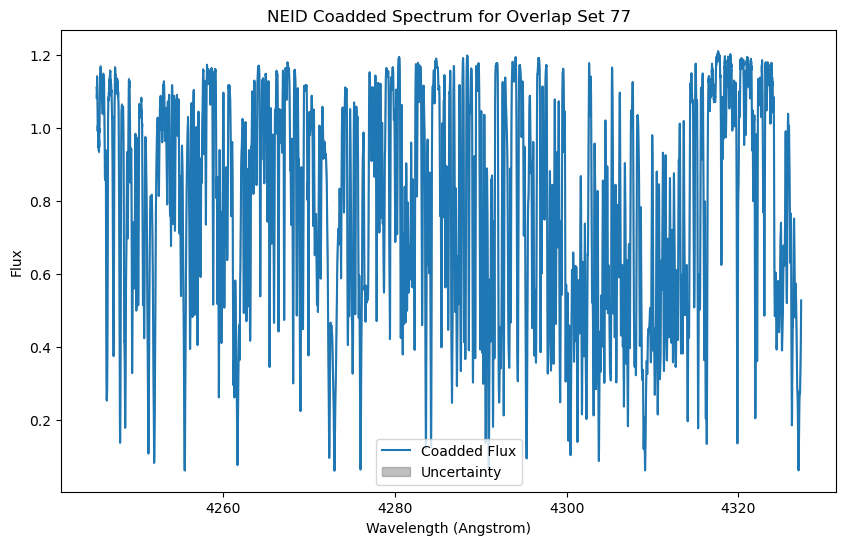

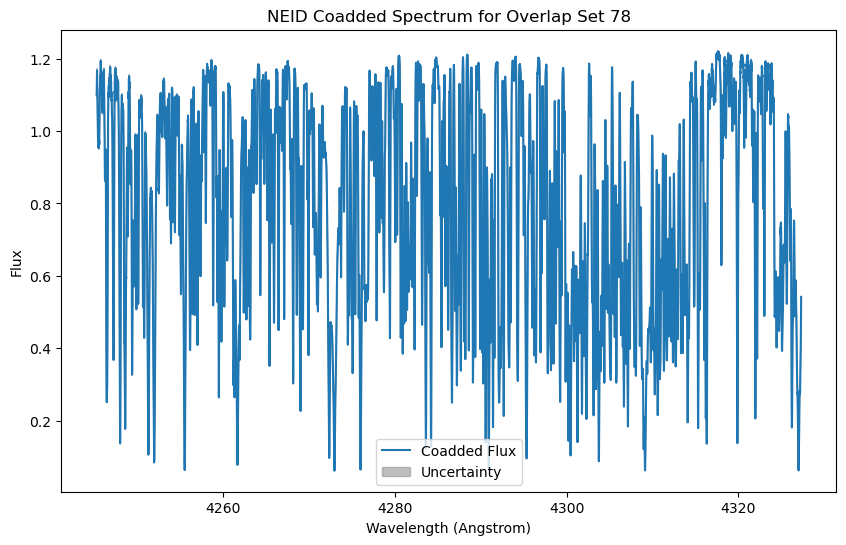

In [95]:
#for the items in neid_coadds with data, plot the coadded fluxes with uncertainties as a function of wavelength
import matplotlib.pyplot as plt

o=30

for i in range(len(neid_coadds)):
    if neid_iscoadd[i]:
        plt.figure(figsize=(10,6))
        plt.plot(neid_wls[i][o], neid_coadds[i][o], label='Coadded Flux')
        #use plt errorbar to plot uncertainties
        #plt.errorbar(neid_wls[i][o], neid_coadds[i][o], yerr=neid_uncerts[i][o], fmt='none', ecolor='gray', alpha=0.5, capsize=2)
        plt.fill_between(neid_wls[i][o], neid_coadds[i][o]-neid_uncerts[i][o], neid_coadds[i][o]+neid_uncerts[i][o], color='gray', alpha=0.5, label='Uncertainty')
        plt.xlabel('Wavelength (Angstrom)')
        plt.ylabel('Flux')
        plt.title(f'NEID Coadded Spectrum for Overlap Set {i+1}')
        #plt.xlim(5820,5840)
        plt.legend()
        plt.show()

In [ ]:
#for the items in neid_coadds with data, plot the coadded fluxes with uncertainties as a function of wavelength
import matplotlib.pyplot as plt

o=68

for i in range(len(neid_coadds)):
    if neid_iscoadd[i]:
        plt.figure(figsize=(10,6))
        plt.plot(neid_wls[i][o], neid_coadds[i][o], label='Coadded Flux')
        #use plt errorbar to plot uncertainties
        plt.errorbar(neid_wls[i][o], neid_coadds[i][o], yerr=neid_uncerts[i][o], fmt='none', ecolor='gray', alpha=0.5, capsize=2)
        #plt.fill_between(neid_wls[i], neid_coadds[i]-neid_uncerts[i], neid_coadds[i]+neid_uncerts[i], color='gray', alpha=0.5, label='Uncertainty')
        plt.xlabel('Wavelength (Angstrom)')
        plt.ylabel('Flux')
        plt.title(f'NEID Coadded Spectrum for Overlap Set {i+1}')
        plt.xlim(5820,5840)
        plt.legend()
        plt.show()